In [4]:
import numpy as np 
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

In [5]:
#  Функции, необходимые в дальнейших расчетах:
from scipy.optimize import curve_fit
def delta(P, k):
    return P*k

def Ung_center(l, w, h, k):
    """Вычисляет модуль Юнга при центральной нагрузке.

    Args:
        l - расстояние между призмами, см
        w - ширина, мм
        h - толщина, мм
        k - значение коэффициента в уравнении delta = k*P, где P - нагрузка, где delta [м*10^(-5)]

    Returns:
        Значение модуля Юнга
    """
    return l**3*10**(-6)/(4*w*h**3*k*10**(-17))

def Ung_shift(a, b, w, h, k):
    """Вычисляет модуль Юнга при нецентральной нагрузке.

    Args:
        a - расстояние от точки приложения до левой призмы, см
        b - расстояние от точки приложения до правой призмы, см
        w - ширина, мм
        h - толщина, мм
        k - значение коэффициента в уравнении delta = k*P, где P - нагрузка, где delta [м*10^(-5)]

    Returns:
        Значение модуля Юнга
    """
    return 4*a**2*b**2*10**(-8)/(w*h**3*k*(a+b)*10**(-19))

# Опеределение модуля Юнга металлической балки

## Измерение 1: нагрузка по центру

In [6]:
%%capture
# Данные (перенесены из Latex) для измерения 1
'''
    1& 5087& 67 & \\
    2& 5000+5087 & 140 & \\
    3& 5000+5087+5030 & 208 & \\
    4& 5000+5087+5030+4679+5035 & 340 & \\
    5& 5000+5087+5030+4679+5035+4618+4636 & 473 & \\

l = 50.4 cm
w = 21.4
h = 4.4
'''

Модуль Юнга:[1.2478558e+11]


/tmp/ipykernel_170062/1424838595.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


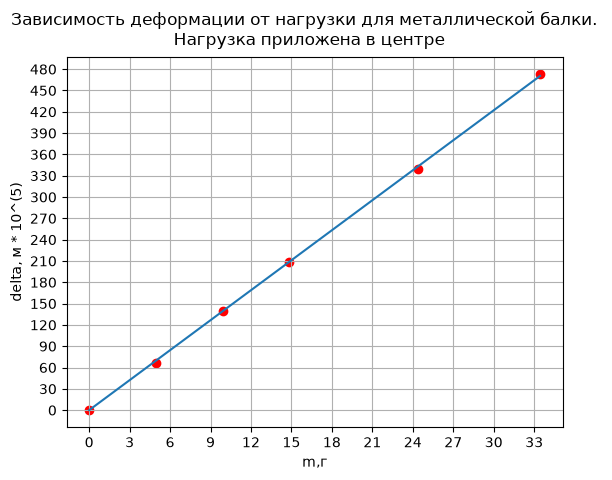

In [7]:
# Experiment 1
exp_1_force = np.array([0, 5087, 5000+5087, 5000+5087+5030, 5000+5087+5030+4679+5035, 5000+5087+5030+4679+5035+4618+4636])*10**(-4)*9.81
exp_1_delta = np.array([0, 67, 140, 208, 340, 473])

popt_1, no = curve_fit(delta,exp_1_force,exp_1_delta)
Ung_1 = Ung_center(l=50.4, w=21.4, h=4.4, k=popt_1)
print(f"Модуль Юнга:{Ung_1}")
fig, ax = plt.subplots()
ax.scatter(exp_1_force, exp_1_delta,color='red')
ax.plot(exp_1_force, popt_1*exp_1_force)
ax.set_xlabel('m,г')
ax.set_ylabel('delta, м * 10^(5)')
ax.xaxis.set_major_locator(ticker.MultipleLocator(3))
ax.yaxis.set_major_locator(ticker.MultipleLocator(30))
ax.grid(True)
fig.suptitle('Зависимость деформации от нагрузки для металлической балки. \n Нагрузка приложена в центре')
fig.show()

## Измерение 2: нагрузка в точке, смещенной относительно центра

In [8]:
'''
1& 5035& 69 & \\
2& 5035+4679& 130 & \\
3& 5035+4679+4618& 198 & \\
4& 5035+4679+4618+5087 & 261 & \\
5& 5035+4679+4618+5087+4723+5020 & 403 & \\
6& 5035+4679+4618+5087+4723+5020+5030 & 466 & \\

l = 50.4 cmм * 10^(5)
a = 27; b= 23.4
w = 21.4
h = 4.4
'''

'\n1& 5035& 69 & \\\n2& 5035+4679& 130 & \\\n3& 5035+4679+4618& 198 & \\\n4& 5035+4679+4618+5087 & 261 & \\\n5& 5035+4679+4618+5087+4723+5020 & 403 & \\\n6& 5035+4679+4618+5087+4723+5020+5030 & 466 & \\\n\nl = 50.4 cmм * 10^(5)\na = 27; b= 23.4\nw = 21.4\nh = 4.4\n'

Отношение коэффициентов k в формуле delta = k*P для центральной и смещенной нагрузки [1.00981647]
Модуль Юнга:[1.24727993e+11]


/tmp/ipykernel_170062/1655477572.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


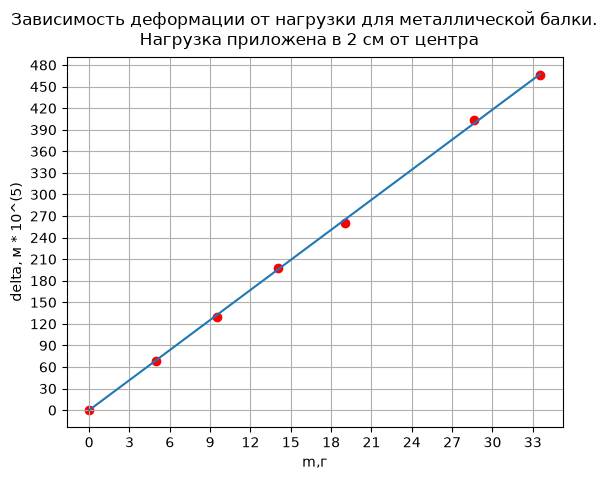

In [9]:
exp_2_force = np.array([0, 5035, 5035+4679,5035+4679+4618,5035+4679+4618+5087,5035+4679+4618+5087+4723+5020,5035+4679+4618+5087+4723+5020+5030])*9.81*10**(-4)
exp_2_delta = np.array([0, 69,130,198,261,403,466])
popt_2, no = curve_fit(delta,exp_2_force,exp_2_delta)

print(f"Отношение коэффициентов k в формуле delta = k*P для центральной и смещенной нагрузки {popt_1/popt_2}")
'''
popt_2 = 4a^2*b^2/(ab^3*l*E)
'''
Ung_2 = Ung_shift(a=27, b=23.4, w=21.4, h=4.4, k=popt_2)
print(f"Модуль Юнга:{Ung_2}")
fig, ax = plt.subplots()
ax.scatter(exp_2_force, exp_2_delta,color='red')
ax.plot(exp_2_force, popt_2*exp_2_force)
ax.set_xlabel('m,г')
ax.set_ylabel('delta, м * 10^(5)')
ax.xaxis.set_major_locator(ticker.MultipleLocator(3))
ax.yaxis.set_major_locator(ticker.MultipleLocator(30))
ax.grid(True)
fig.suptitle('Зависимость деформации от нагрузки для металлической балки. \n Нагрузка приложена в 2 см от центра')
fig.show()


# Опеределение модуля Юнга деревяной балки 1

## Измерение 3: Нагрузка по центру

In [10]:
'''
1& 5035& 39 & \\
2& 5035+4679& 87 & \\
3& 5035+4679+4618& 138 & \\
4& 5035+4679+4618+5087 & 189 & \\
5& 5035+4679+4618+5087+4723+5020 & 284 & \\
6& 5035+4679+4618+5087+4723+5020+5030 & 339 & \\

ширина 20мм
толщина 10,1 mm
'''

'\n1& 5035& 39 & \\\n2& 5035+4679& 87 & \\\n3& 5035+4679+4618& 138 & \\\n4& 5035+4679+4618+5087 & 189 & \\\n5& 5035+4679+4618+5087+4723+5020 & 284 & \\\n6& 5035+4679+4618+5087+4723+5020+5030 & 339 & \\\n\nширина 20мм\nтолщина 10,1 mm\n'

Модуль Юнга:[1.56128253e+10]


/tmp/ipykernel_170062/1408700315.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


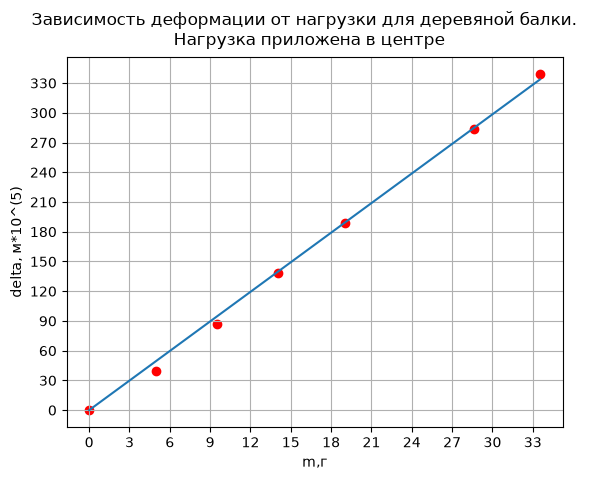

In [11]:
exp_3_force = np.array([0, 5035, 5035+4679,5035+4679+4618,5035+4679+4618+5087,5035+4679+4618+5087+4723+5020,5035+4679+4618+5087+4723+5020+5030])*9.81*10**(-4)
exp_3_delta = np.array([0,39,87,138,189,284,339])
popt_3, no = curve_fit(delta,exp_3_force,exp_3_delta)
'''
popt = l^3/(4ab^3E)
'''
Ung_3 = Ung_center(l=50.4, h=10.1, w=20, k=popt_3)
print(f"Модуль Юнга:{Ung_3}")
fig, ax = plt.subplots()
ax.scatter(exp_3_force, exp_3_delta,color='red')
ax.plot(exp_3_force, popt_3*exp_3_force)
ax.set_xlabel('m,г')
ax.set_ylabel('delta, м*10^(5)')
ax.xaxis.set_major_locator(ticker.MultipleLocator(3))
ax.yaxis.set_major_locator(ticker.MultipleLocator(30))
ax.grid(True)
fig.suptitle('Зависимость деформации от нагрузки для деревяной балки. \n Нагрузка приложена в центре')
fig.show()

## Измерение 4: Нагрузка со смещением 4,8 см

In [12]:
'''
    1& 5035& 34 & \\
    2& 5035+4679&  & \\
    3& 5035+4679+4618& 128 & \\
    4& 5035+4679+4618+5087 & 175 & \\
    5& 5035+4679+4618+5087+4723+5020 & & \\
    6& 5035+4679+4618+5087+4723+5020+5030 & 318 & \\
'''

'\n    1& 5035& 34 & \\\n    2& 5035+4679&  & \\\n    3& 5035+4679+4618& 128 & \\\n    4& 5035+4679+4618+5087 & 175 & \\\n    5& 5035+4679+4618+5087+4723+5020 & & \\\n    6& 5035+4679+4618+5087+4723+5020+5030 & 318 & \\\n'

Модуль Юнга:[1.54491904e+10]


/tmp/ipykernel_170062/3691348247.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


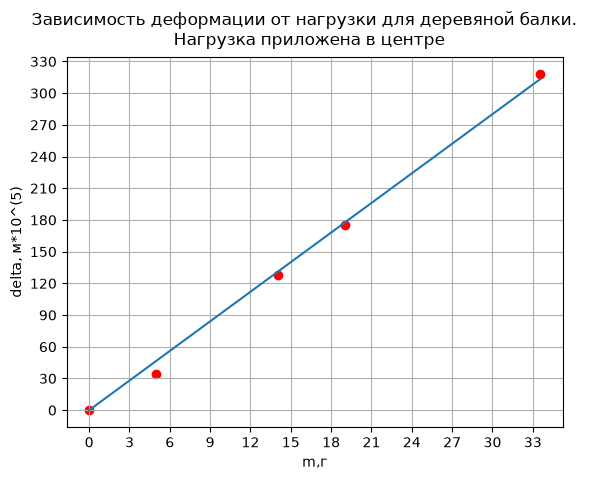

In [13]:
exp_4_force = np.array([0, 5035, 5035+4679+4618,5035+4679+4618+5087, 5035+4679+4618+5087+4723+5020+5030])*9.81*10**(-4)
exp_4_delta = np.array([0, 34, 128, 175, 318])
popt_4, no = curve_fit(delta,exp_4_force,exp_4_delta)
'''
popt = l^3/(4ab^3E)
'''
Ung_4 = Ung_shift(a=30, b=50.4-30, h=10.1, w=20, k=popt_4)
print(f"Модуль Юнга:{Ung_4}")
fig, ax = plt.subplots()
ax.scatter(exp_4_force, exp_4_delta,color='red')
ax.plot(exp_4_force, popt_4*exp_4_force)
ax.set_xlabel('m,г')
ax.set_ylabel('delta, м*10^(5)')
ax.xaxis.set_major_locator(ticker.MultipleLocator(3))
ax.yaxis.set_major_locator(ticker.MultipleLocator(30))
ax.grid(True)
fig.suptitle('Зависимость деформации от нагрузки для деревяной балки. \n Нагрузка приложена в центре')
fig.show()

## Измерение 5: измерение деформации перевернутой (относительно прошлых измерений) балки

In [14]:
'''
    1& 5035& 49 & \\
    2& 5035+4679& 98 & \\
    3& 5035+4679+4618&  & \\
    4& 5035+4679+4618+5087 & 176 & \\
    5& 5035+4679+4618+5087+4723+5020 &  & \\
    6& 5035+4679+4618+5087+4723+5020+5030 & 322 & \\
'''

'\n    1& 5035& 49 & \\\n    2& 5035+4679& 98 & \\\n    3& 5035+4679+4618&  & \\\n    4& 5035+4679+4618+5087 & 176 & \\\n    5& 5035+4679+4618+5087+4723+5020 &  & \\\n    6& 5035+4679+4618+5087+4723+5020+5030 & 322 & \\\n'

Модуль Юнга:[1.62443159e+10]


/tmp/ipykernel_170062/2088916990.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


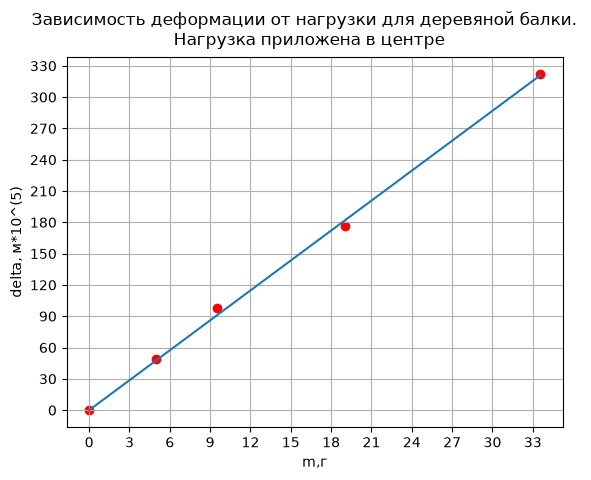

In [15]:
exp_5_force = np.array([0, 5035, 5035+4679, 5035+4679+4618+5087, 5035+4679+4618+5087+4723+5020+5030])*9.81*10**(-4)
exp_5_delta = np.array([0, 49, 98, 176, 322])
popt_5, no = curve_fit(delta,exp_5_force,exp_5_delta)
'''
popt = l^3/(4ab^3E)
'''
Ung_5 = Ung_center(l=50.4, h=10.1, w=20, k=popt_5)
print(f"Модуль Юнга:{Ung_5}")
fig, ax = plt.subplots()
ax.scatter(exp_5_force, exp_5_delta,color='red')
ax.plot(exp_5_force, popt_5*exp_5_force)
ax.set_xlabel('m,г')
ax.set_ylabel('delta, м*10^(5)')
ax.xaxis.set_major_locator(ticker.MultipleLocator(3))
ax.yaxis.set_major_locator(ticker.MultipleLocator(30))
ax.grid(True)
fig.suptitle('Зависимость деформации от нагрузки для деревяной балки. \n Нагрузка приложена в центре')
fig.show()

# Определение модуля Юнга деревяной балки 2

## Измерение 6 (нагрузка по центру)

In [16]:
'''
    1& 5035& 50\\
    2& 5035+4679&  109& \\
    3& 5035+4679+4618&  & \\
    4& 5035+4679+4618+5087 & 176 & \\
    5& 5035+4679+4618+5087+4723+5020 &  & \\
    6& 5035+4679+4618+5087+4723+5020+5030 & 331 & \\

20 мм ширина
9,5 мм толщина
'''

'\n    1& 5035& 50\\\n    2& 5035+4679&  109& \\\n    3& 5035+4679+4618&  & \\\n    4& 5035+4679+4618+5087 & 176 & \\\n    5& 5035+4679+4618+5087+4723+5020 &  & \\\n    6& 5035+4679+4618+5087+4723+5020+5030 & 331 & \\\n\n20 мм ширина\n9,5 мм толщина\n'

[9.81848519] [[0.05695176]]
Модуль Юнга:[1.90101838e+10]


/tmp/ipykernel_170062/1239989020.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


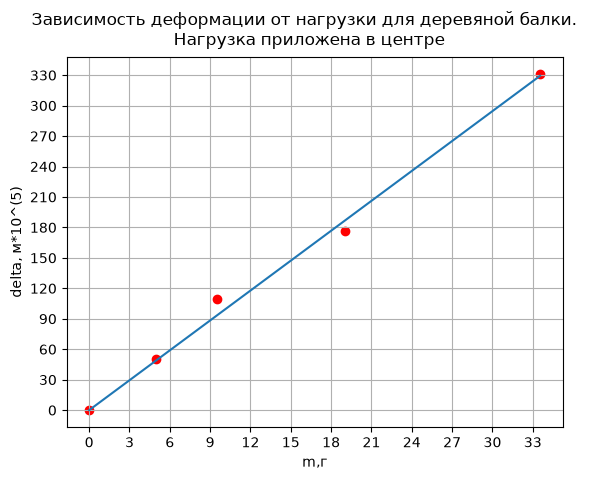

In [17]:
exp_6_force = np.array([0, 5035, 5035+4679, 5035+4679+4618+5087, 5035+4679+4618+5087+4723+5020+5030])*9.81*10**(-4)
exp_6_delta = np.array([0, 50, 109, 176, 331])
popt_6, no = curve_fit(delta,exp_6_force,exp_6_delta)
print(popt_6, no)
'''
popt = l^3/(4ab^3E)
'''
Ung_6 = Ung_center(l=50.4, h=9.5, w=20, k=popt_6)
print(f"Модуль Юнга:{Ung_6}")
fig, ax = plt.subplots()
ax.scatter(exp_6_force, exp_6_delta,color='red')
ax.plot(exp_6_force, popt_6*exp_6_force)
ax.set_xlabel('m,г')
ax.set_ylabel('delta, м*10^(5)')
ax.xaxis.set_major_locator(ticker.MultipleLocator(3))
ax.yaxis.set_major_locator(ticker.MultipleLocator(30))
ax.grid(True)
fig.suptitle('Зависимость деформации от нагрузки для деревяной балки. \n Нагрузка приложена в центре')
fig.show()

# Определение модуля Юнга проволки

In [18]:
    '''
    1& 5044& 19.6 \\
    2& 5044+2456& 22.3 \\
    3& 5044+2456+2453+2455& 27.3 \\
    4& 5044+2456+2453+2455+2461+2458 & 31.8 \\
    5& 5044+2456+2453+2455+2461+2458+2453+2456 & 36.2 \\
    6& 5044+2456+2453+2455+2461+2458+2453+2456+2455+2456 & 40.6 \\
    7& 5044+2456+2453+2455+2461+2458+2453+2456+2455+2456+2456 & 42.8 \\
    '''

'\n1& 5044& 19.6 \\\n2& 5044+2456& 22.3 \\\n3& 5044+2456+2453+2455& 27.3 \\\n4& 5044+2456+2453+2455+2461+2458 & 31.8 \\\n5& 5044+2456+2453+2455+2461+2458+2453+2456 & 36.2 \\\n6& 5044+2456+2453+2455+2461+2458+2453+2456+2455+2456 & 40.6 \\\n7& 5044+2456+2453+2455+2461+2458+2453+2456+2455+2456+2456 & 42.8 \\\n'

[ 5.67412352e-05 -2.37478720e-04]


Text(0.5, 0, 'нагрузка, Н')

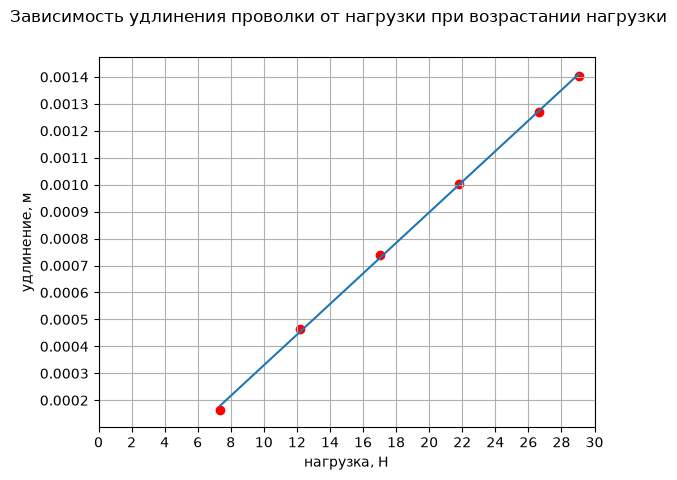

In [28]:
# первая точка исключена из расчета, так как на этом этапе проволка выпрямляется, не удлиняется
wire_force_up = np.array([5044+2456, 5044+2456+2453+2455, 5044+2456+2453+2455+2461+2458, 5044+2456+2453+2455+2461+2458+2453+2456, 
5044+2456+2453+2455+2461+2458+2453+2456+2455+2456, 5044+2456+2453+2455+2461+2458+2453+2456+2455+2456+2456])*9.81*10**(-4)
# n = 2*delta_s
n_sm_up = np.array([19.6, 22.3, 27.3, 31.8, 36.2, 40.6, 42.8])*10**(-2)
n_sm_up = (n_sm_up - np.array([n_sm_up[0] for i in range(len(n_sm_up))]))[1:]

def deformation(n:np.ndarray, r=15/10, h=124):
    delta_l = n*r/(2*h)
    return delta_l

def delta_with_bias(P, k, b):
    return P*k+b

delta_l = deformation(n_sm_up)

res, cov = curve_fit(delta_with_bias, wire_force_up, delta_l)

print(res)
fig, ax = plt.subplots()
ax.scatter(wire_force_up, delta_l, color='red')
ax.set_xlim(0,30)
ax.plot(wire_force_up, wire_force_up*res[0]+res[1])
ax.grid(True)
ax.xaxis.set_major_locator(ticker.MultipleLocator(2))
ax.yaxis.set_major_locator(ticker.MultipleLocator(0.0001))
fig.suptitle('Зависимость удлинения проволки от нагрузки при возрастании нагрузки')
ax.set_ylabel('удлинение, м')
ax.set_xlabel('нагрузка, Н')



In [ ]:
''' 
    @Номер замера & @Масса груза, г * 10 & @ Смещение по шкале в см \\
    1& 5044+2456+2453+2455+2461+2458+2453+2456+2455+2456+2456 & 42.8 \\
    2& 5044+2456+2453+2455+2461+2458+2453+2456+2455+2456 & 40.7 \\
    3& 5044+2456+2453+2455+2461+2458+2453+2456 & 36.3 \\
    4& 5044+2456+2453+2455+2461+2458 & 31.8 \\
    5& 5044+2456+2453+2455& 27.2 \\
    6& 5044+2456& 22.5 \\
    7& 5044& 19.5 \\
'''

' \n    @Номер замера & @Масса груза, г * 10 & @ Смещение по шкале в см \\\n    1& 5044+2456+2453+2455+2461+2458+2453+2456+2455+2456+2456 & 42.8 \\\n    2& 5044+2456+2453+2455+2461+2458+2453+2456+2455+2456 & 40.7 \\\n    3& 5044+2456+2453+2455+2461+2458+2453+2456 & 36.3 \\\n    4& 5044+2456+2453+2455+2461+2458 & 31.8 \\\n    5& 5044+2456+2453+2455& 27.2 \\\n    6& 5044+2456& 22.5 \\\n    7& 5044& 19.5 \\\n'

[ 5.66381460e-05 -2.26447224e-04]


Text(0.5, 0, 'нагрузка, Н')

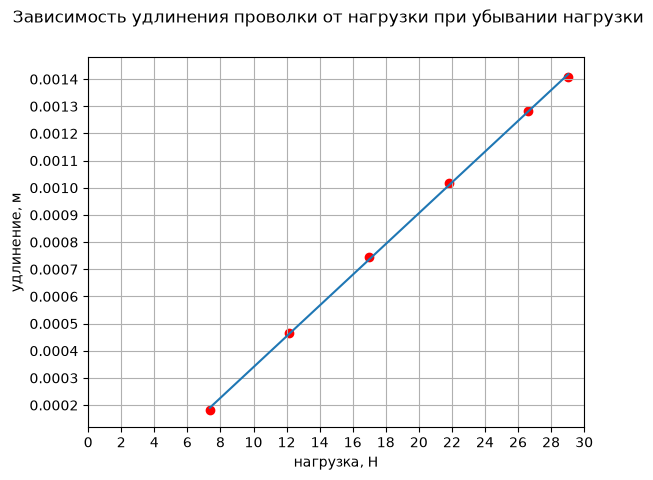

In [27]:
wire_force_down = np.array([5044+2456, 5044+2456+2453+2455, 5044+2456+2453+2455+2461+2458, 5044+2456+2453+2455+2461+2458+2453+2456, 
5044+2456+2453+2455+2461+2458+2453+2456+2455+2456, 5044+2456+2453+2455+2461+2458+2453+2456+2455+2456+2456])*9.81*10**(-4)
wire_force_down.sort(descending=True)
n_sm_down = np.array([42.8, 40.7, 36.3, 31.8, 27.2, 22.5, 19.5])*10**(-2)
n_sm_down = (n_sm_down - np.array([n_sm_down[-1] for i in range(len(n_sm_down))]))[:-1]
delta_l_down = deformation(n_sm_down)

res_down, no = curve_fit(delta_with_bias, wire_force_down, delta_l_down)

print(res_down)
fig, ax = plt.subplots()
ax.scatter(wire_force_down, delta_l_down, color='red')
ax.plot(wire_force_down, wire_force_down*res_down[0] + res_down[1])
ax.grid(True)
ax.xaxis.set_major_locator(ticker.MultipleLocator(2))
ax.yaxis.set_major_locator(ticker.MultipleLocator(0.0001))
ax.set_xlim(0,30)
fig.suptitle('Зависимость удлинения проволки от нагрузки при убывании нагрузки')
ax.set_ylabel('удлинение, м')
ax.set_xlabel('нагрузка, Н')

In [ ]:
k_rigidity = 1/np.mean([res[0], res_down[0]])
print(f"Коэффициент жёсткости {k_rigidity} Н/м")
'E = kl/s'
E = k_rigidity*177*10**(-2)/(np.pi*0.46*10**(-6)/4)
print(f"Модуль Юнга {E*10**(-9)} Гпа")


Коэффициент жёсткости 17639.891659067634 Н/м
Модуль Юнга 86.42143368814979 Гпа


## Расчет относителньой ошибки для коэффициента жесткости и Юнга

In [ ]:
cov

array([[ 4.46791891e-13, -8.48999924e-12],
       [-8.48999924e-12,  1.87624675e-10]])

In [ ]:
sigma_rand = cov[0][1]**(1/2)/(6**(1/2))
'''
F = k*delta_l = k*n*r/2h => k = F*2h/(n*r)

'''
sigma_h = sigma_syst_h = 0.001
 


# Опыт 1.3.2

In [ ]:
'''
    1 & 3 & 10 & 2,384 & \\
    2 & 3 & 5 & 2,349 & \\
    3 & 5 & 2,883 & \\
    4 & 7 & 3,392 & \\
    5 & 9 & 3,984 & \\
'''

[0.14177272 4.48917087]


Text(0, 0.5, 'T^2, c^2')

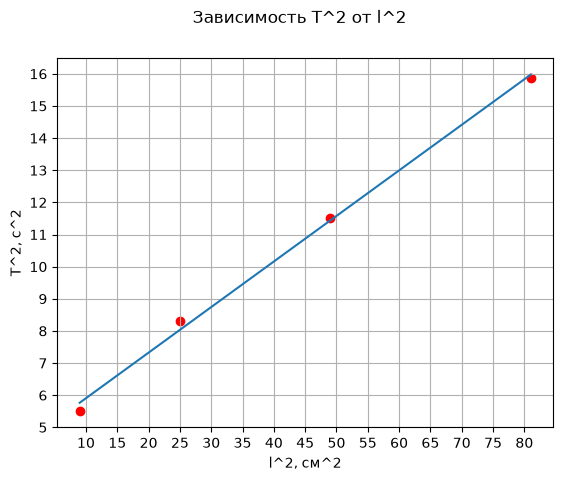

In [26]:
l = np.array([3,5,7,9])
T = np.array([2.349, 2.883, 3.392, 3.984])
res, cov = curve_fit(delta_with_bias, l**2, T**2)

print(res)
fig, ax = plt.subplots()
ax.scatter(l**2, T**2, color='red')
ax.plot(l**2, l**2 * res[0] + res[1])
ax.grid(True)
ax.xaxis.set_major_locator(ticker.MultipleLocator(5))
ax.yaxis.set_major_locator(ticker.MultipleLocator(1))
#ax.set_xlim(0,30)
fig.suptitle(' Зависимость T^2 от l^2')
ax.set_xlabel('l^2, см^2')
ax.set_ylabel('T^2, c^2')


In [30]:
rotation_mod = np.pi*4*(377.5+373.1)/res[0]
print(f"модуль кручения = {rotation_mod}")

модуль кручения = 166233916.99672294


In [33]:
32*175*166233916/(np.pi*3.01**4*10**(-4))

36098720403844.48